# Sales Prediction Using Python

**CodeAlpha Data Science Internship**

## 1. Project Overview

Sales prediction is an important application of data science that helps businesses understand how advertising investments influence sales performance.

This project aims to analyze advertising expenditure across different marketing channels and use machine learning techniques to predict sales based on available marketing and business factors.

## 2. Project Objectives

- Understand and explore the sales and advertising dataset.
- Clean and preprocess the collected data.
- Perform Exploratory Data Analysis (EDA).
- Identify relationships between advertising expenditure and sales.
- Perform feature selection and feature engineering.
- Develop and compare multiple regression models.
- Evaluate model performance using appropriate metrics.
- Analyze how changes in advertising expenditure affect predicted sales.
- Generate actionable marketing insights and budget recommendations.

## 3. Technologies Used

- **Programming Language:** Python
- **Development Environment:** Visual Studio Code
- **Notebook Environment:** Jupyter Notebook
- **Data Manipulation:** NumPy, Pandas
- **Data Visualization:** Matplotlib, Seaborn
- **Machine Learning:** Scikit-learn
- **Statistical Analysis:** SciPy, Statsmodels

## 4. Project Workflow

1. Data Collection and Inspection
2. Data Cleaning and Preprocessing
3. Exploratory Data Analysis
4. Feature Selection and Engineering
5. Model Development
6. Model Evaluation and Comparison
7. Advertising Impact Analysis
8. Marketing Insights and Recommendations

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy
import statsmodels

print("All libraries imported successfully!")

print("\nLibrary Versions:")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Statsmodels:", statsmodels.__version__)

All libraries imported successfully!

Library Versions:
NumPy: 2.5.4
Pandas: 3.1.0
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-learn: 1.9.1
SciPy: 1.18.1
Statsmodels: 0.15.0


## 5. Dataset Loading and Initial Inspection

The dataset is loaded using Pandas to understand its structure, dimensions, column names, data types, and sample records.

Initial inspection helps identify the available advertising variables and the target variable (Sales) before beginning data preprocessing.

In [3]:
import os

print("Project files:")
print(os.listdir())

Project files:
['.venv', 'Advertising.csv', 'Sales_Prediction.ipynb']


In [4]:
df = pd.read_csv("Advertising.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (200, 5)

Column Names:
['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']

First 5 Rows:


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB

Statistical Summary:


,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


## 6. Data Cleaning and Preprocessing

Data cleaning is performed to improve data quality and ensure that the dataset is suitable for analysis and machine learning.

This stage includes checking missing values, duplicate records, inconsistent data types, and potential outliers.

In [6]:
print("Missing Values:")
display(df.isnull().sum())

Missing Values:


Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

In [7]:
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape After Removing Duplicates:", df.shape)

Duplicate Rows: 0
Shape After Removing Duplicates: (200, 5)


In [8]:
print(df.dtypes)

Unnamed: 0      int64
TV            float64
Radio         float64
Newspaper     float64
Sales         float64
dtype: object


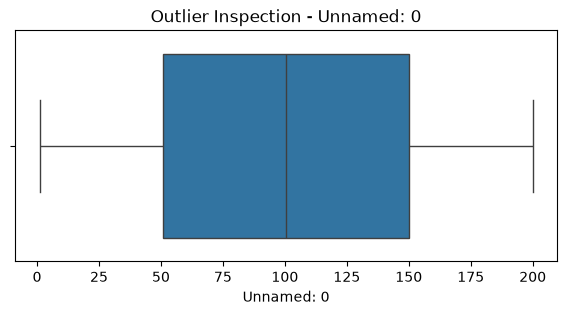

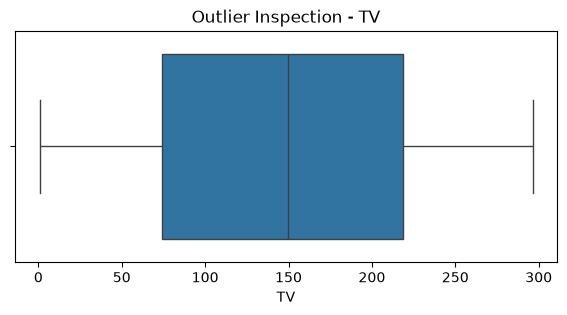

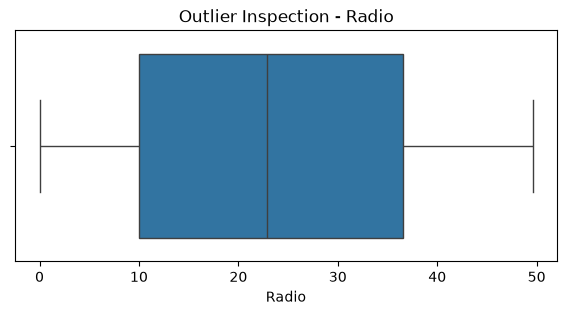

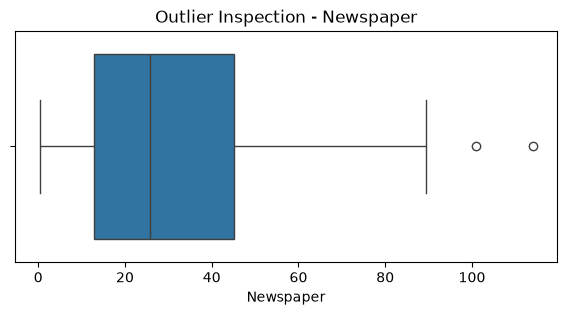

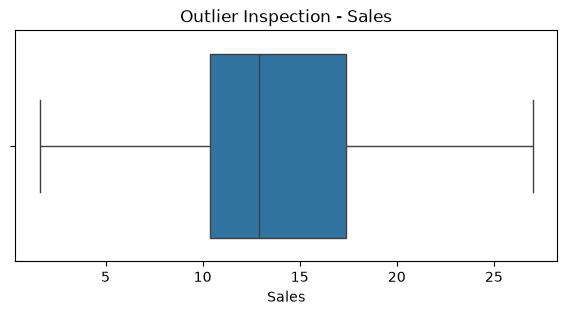

In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Inspection - {col}")
    plt.show()

## 7. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the distribution of variables and discover relationships between advertising expenditure and sales.

Visualizations help identify patterns, trends, correlations, and potentially influential advertising channels.

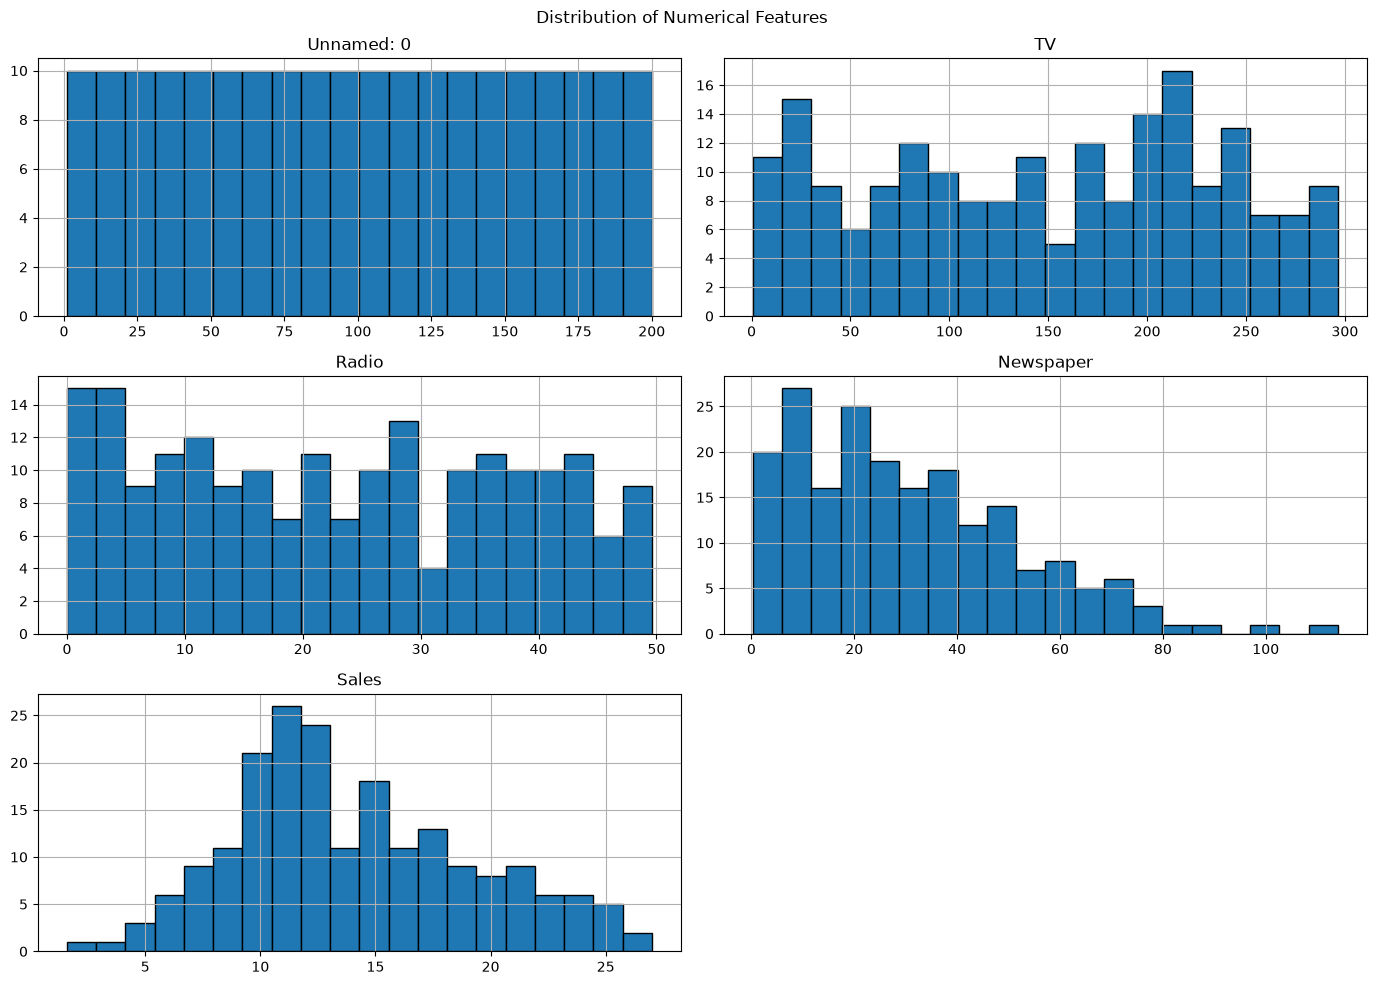

In [10]:
df.select_dtypes(include=np.number).hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

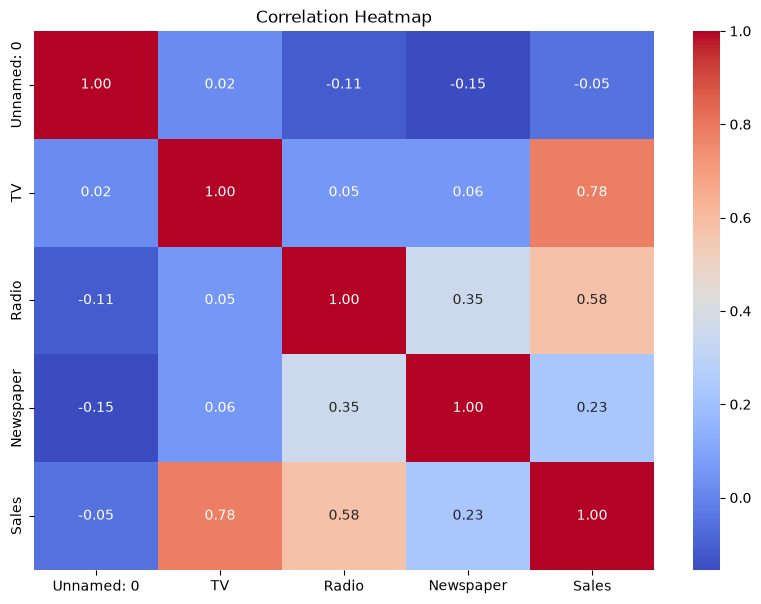

In [11]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

### 7.3.1 Relationship Between Advertising Channels and Sales

Scatterplots are used to examine the relationship between individual advertising channels and sales.

The analysis focuses on TV, Radio, and Newspaper advertising expenditure to understand how changes in marketing investments are associated with sales performance.

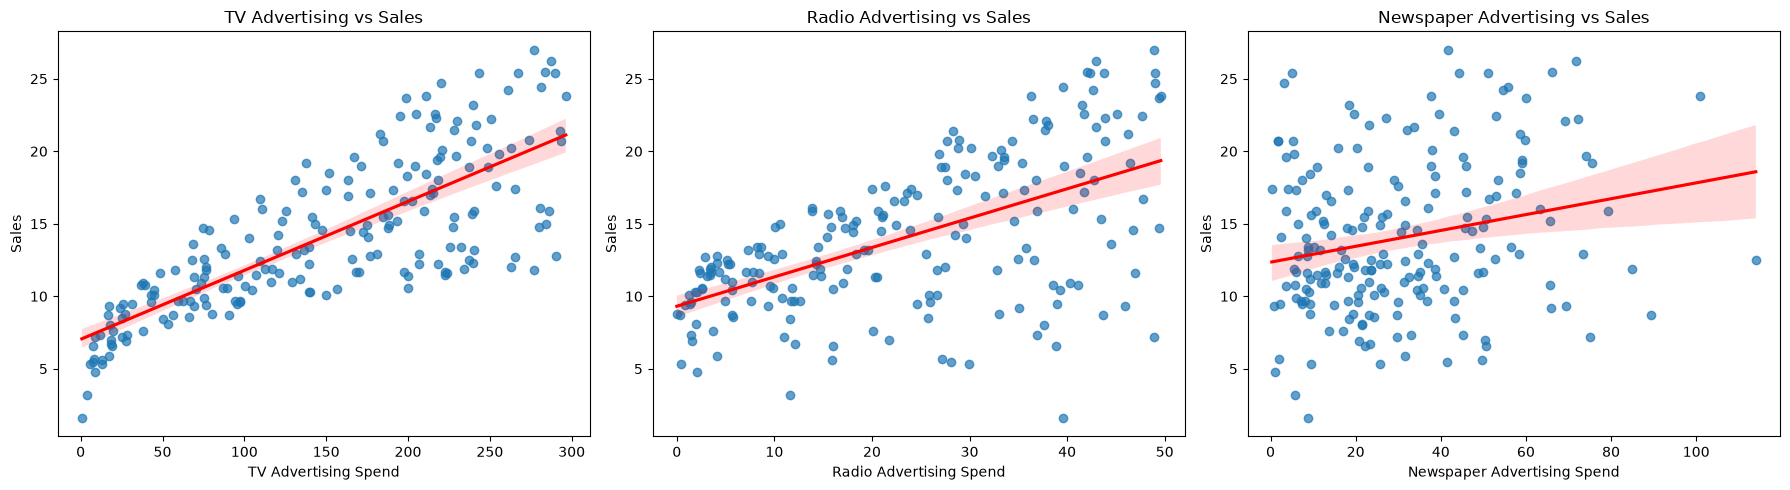

In [16]:
advertising_channels = ["TV", "Radio", "Newspaper"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, channel in zip(axes, advertising_channels):
    sns.regplot(
        data=df,
        x=channel,
        y="Sales",
        ax=ax,
        scatter_kws={"alpha": 0.7},
        line_kws={"color": "red"}
    )

    ax.set_title(f"{channel} Advertising vs Sales")
    ax.set_xlabel(f"{channel} Advertising Spend")
    ax.set_ylabel("Sales")

plt.tight_layout()
plt.show()

### 7.3.3 Pairwise Relationship Analysis

A pairplot provides a visual representation of relationships between all numerical variables in the dataset.

It helps identify correlations, distributions, and potential patterns that may influence sales prediction.

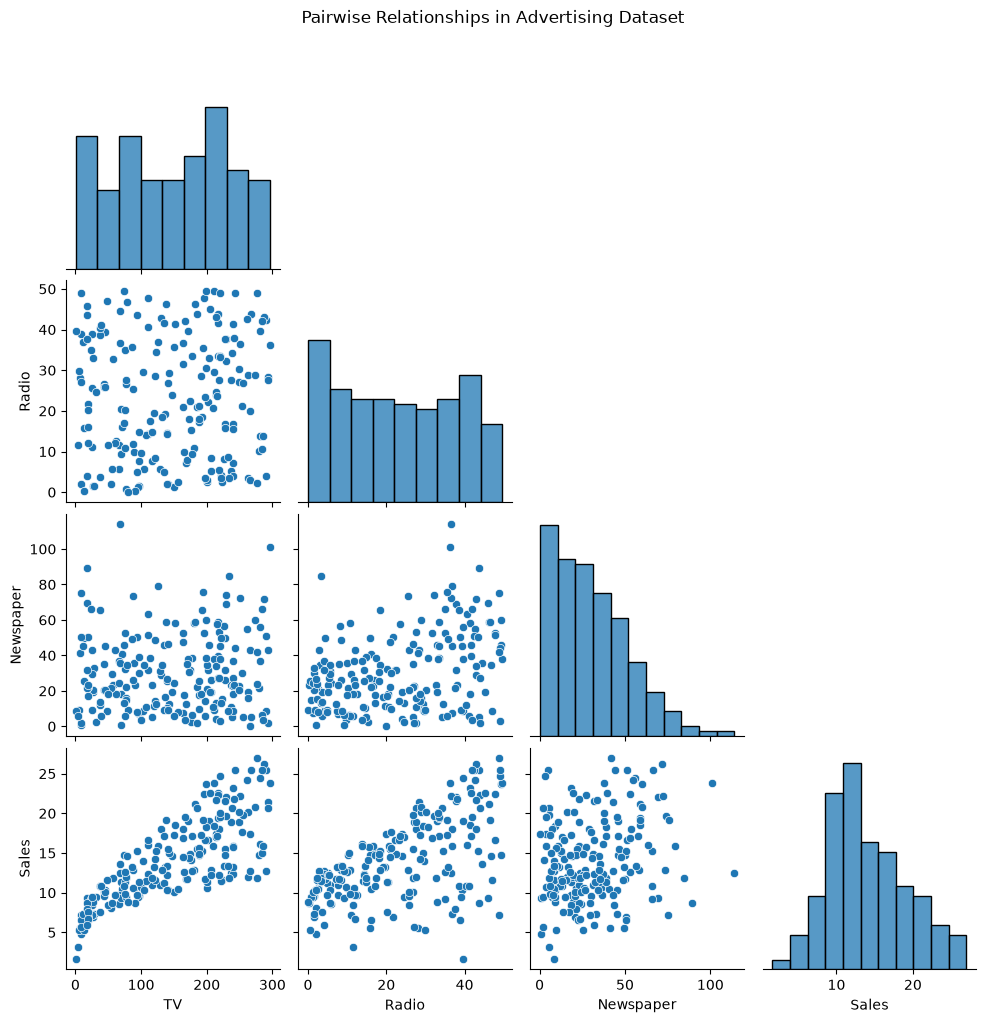

In [17]:
sns.pairplot(
    df[["TV", "Radio", "Newspaper", "Sales"]],
    diag_kind="hist",
    corner=True
)

plt.suptitle(
    "Pairwise Relationships in Advertising Dataset",
    y=1.02
)

plt.show()

### 7.4 Correlation Analysis

Correlation analysis is performed to understand the strength and direction of linear relationships between advertising expenditure and sales.

A correlation heatmap provides a visual summary of these relationships and helps identify potentially useful predictors for the regression models.

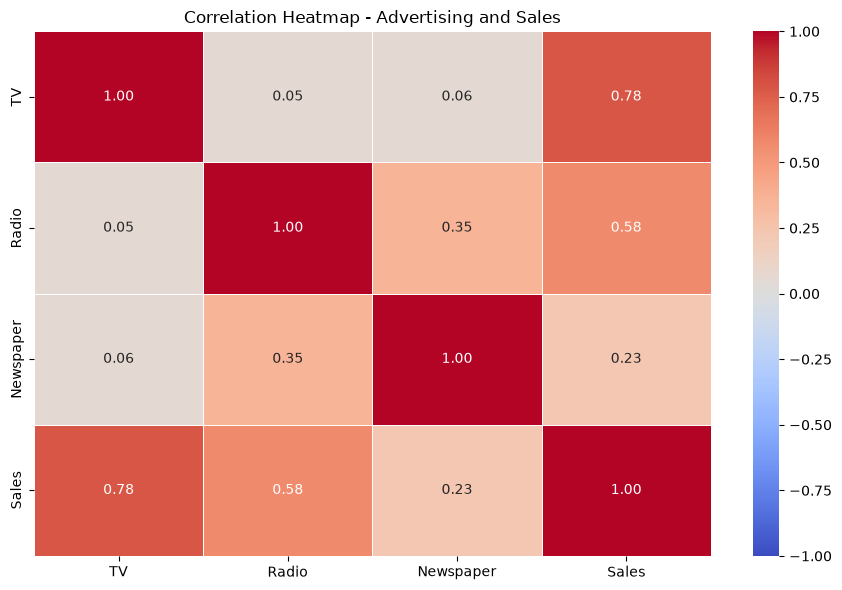

In [18]:
correlation_matrix = df[
    ["TV", "Radio", "Newspaper", "Sales"]
].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Advertising and Sales")
plt.tight_layout()
plt.show()

In [19]:
sales_correlation = correlation_matrix["Sales"].drop("Sales")

print("Correlation of Advertising Channels with Sales:")
display(
    sales_correlation.sort_values(
        ascending=False
    ).to_frame(name="Correlation with Sales")
)

Correlation of Advertising Channels with Sales:


,Correlation with Sales
TV,0.782224
Radio,0.576223
Newspaper,0.228299


## 8. Feature Selection and Engineering

Feature selection identifies the most relevant variables for predicting sales, while feature engineering creates additional variables that may improve model performance.

In this project, we examine multicollinearity among advertising channels, calculate Variance Inflation Factors (VIF), and explore interaction terms between advertising channels.

In [20]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Updated Columns:")
print(df.columns.tolist())

print("\nUpdated Shape:", df.shape)

Updated Columns:
['TV', 'Radio', 'Newspaper', 'Sales']

Updated Shape: (200, 4)


In [21]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (200, 3)
Target Shape: (200,)


In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()

vif_data["Feature"] = X.columns

vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

display(vif_data)

,Feature,VIF
0,TV,1.004611
1,Radio,1.144952
2,Newspaper,1.145187


In [23]:
df["Total_Ad_Spend"] = (
    df["TV"] + df["Radio"] + df["Newspaper"]
)

display(df[["TV", "Radio", "Newspaper", "Total_Ad_Spend"]].head())

,TV,Radio,Newspaper,Total_Ad_Spend
0,230.1,37.8,69.2,337.1
1,44.5,39.3,45.1,128.9
2,17.2,45.9,69.3,132.4
3,151.5,41.3,58.5,251.3
4,180.8,10.8,58.4,250.0


In [24]:
df["TV_Radio_Interaction"] = df["TV"] * df["Radio"]

df["TV_Newspaper_Interaction"] = df["TV"] * df["Newspaper"]

df["Radio_Newspaper_Interaction"] = df["Radio"] * df["Newspaper"]

display(df.head())

,TV,Radio,Newspaper,Sales,Total_Ad_Spend,TV_Radio_Interaction,TV_Newspaper_Interaction,Radio_Newspaper_Interaction
0,230.1,37.8,69.2,22.1,337.1,8697.78,15922.92,2615.76
1,44.5,39.3,45.1,10.4,128.9,1748.85,2006.95,1772.43
2,17.2,45.9,69.3,9.3,132.4,789.48,1191.96,3180.87
3,151.5,41.3,58.5,18.5,251.3,6256.95,8862.75,2416.05
4,180.8,10.8,58.4,12.9,250.0,1952.64,10558.72,630.72


## 9. Baseline Model Development

Linear Regression is used as the baseline model for predicting sales from advertising expenditure.

The dataset is divided into training and testing sets. The training data is used to learn relationships between advertising channels and sales, while the testing data evaluates performance on unseen observations.

In [25]:
from sklearn.model_selection import train_test_split

X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 3)
Testing data: (40, 3)


In [26]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

baseline_predictions = linear_model.predict(X_test)

print("Linear Regression trained successfully!")
print("Intercept:", linear_model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_
})

display(coefficients)

Linear Regression trained successfully!
Intercept: 2.9790673381226256


,Feature,Coefficient
0,TV,0.044730
1,Radio,0.189195
2,Newspaper,0.002761


In [27]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

baseline_r2 = r2_score(y_test, baseline_predictions)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("Baseline R2:", baseline_r2)
print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline R2: 0.899438024100912
Baseline MAE: 1.4607567168117606
Baseline RMSE: 1.7815996615334502


## 10. Model Comparison and Optimization

Different regression algorithms are implemented to identify the most suitable model for sales prediction.

The models include Linear Regression, Ridge Regression, Lasso Regression, Polynomial Regression, Random Forest, and Gradient Boosting.

Their performance is compared using cross-validation on the training dataset and evaluated on the independent test dataset.

In [30]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1))
    ]),

    "Polynomial Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", LinearRegression())
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

In [31]:
model_results = []

trained_models = {}

for name, model in models.items():

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    trained_models[name] = model

    model_results.append({
        "Model": name,
        "CV Mean R2": cv_scores.mean(),
        "Test R2": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

model_comparison = pd.DataFrame(model_results)

display(
    model_comparison.sort_values(
        "CV Mean R2",
        ascending=False
    )
)

,Model,CV Mean R2,Test R2,MAE,RMSE
3,Polynomial Regression,0.977239,0.986918,0.526179,0.642581
4,Random Forest,0.970061,0.981813,0.628925,0.757657
5,Gradient Boosting,0.969725,0.983127,0.618742,0.729782
2,Lasso Regression,0.861911,0.898336,1.461273,1.791334
1,Ridge Regression,0.859656,0.898803,1.464301,1.787220
0,Linear Regression,0.859488,0.899438,1.460757,1.781600


In [32]:
best_model_name = model_comparison.loc[
    model_comparison["CV Mean R2"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Selected Model:", best_model_name)

Selected Model: Polynomial Regression


## 11. Final Model Evaluation

The selected regression model is evaluated using multiple performance metrics, including R², Mean Absolute Error, Root Mean Squared Error, and Mean Absolute Percentage Error.

Cross-validation results are also considered to understand the consistency of model performance.

In [33]:
final_predictions = best_model.predict(X_test)

final_r2 = r2_score(y_test, final_predictions)
final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)

print("Selected Model:", best_model_name)
print("R2 Score:", final_r2)
print("MAE:", final_mae)
print("RMSE:", final_rmse)

Selected Model: Polynomial Regression
R2 Score: 0.9869181490609604
MAE: 0.5261794444043735
RMSE: 0.6425809120553617


In [35]:
from sklearn.metrics import mean_absolute_percentage_error

In [36]:
nonzero_mask = np.asarray(y_test) != 0

if nonzero_mask.any():

    final_mape = (
        mean_absolute_percentage_error(
            np.asarray(y_test)[nonzero_mask],
            final_predictions[nonzero_mask]
        ) * 100
    )

    print("MAPE:", final_mape, "%")

else:
    print("MAPE cannot be calculated.")

MAPE: 4.893877124817135 %


### 11.4 Actual vs Predicted Sales

This visualization compares the actual sales values with the values predicted by the selected machine learning model.

A prediction closer to the red diagonal line indicates better model performance.

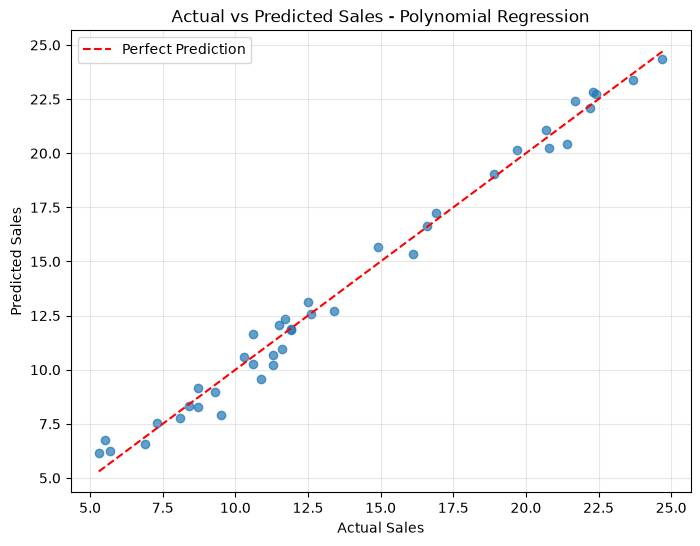

In [37]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, final_predictions, alpha=0.7)

minimum = min(y_test.min(), final_predictions.min())
maximum = max(y_test.max(), final_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title(f"Actual vs Predicted Sales - {best_model_name}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 11.5 Residual Analysis

Residuals represent the difference between actual sales and predicted sales.

Residual = Actual Sales - Predicted Sales

Residual analysis helps identify prediction errors and determine whether the model consistently overestimates or underestimates sales.

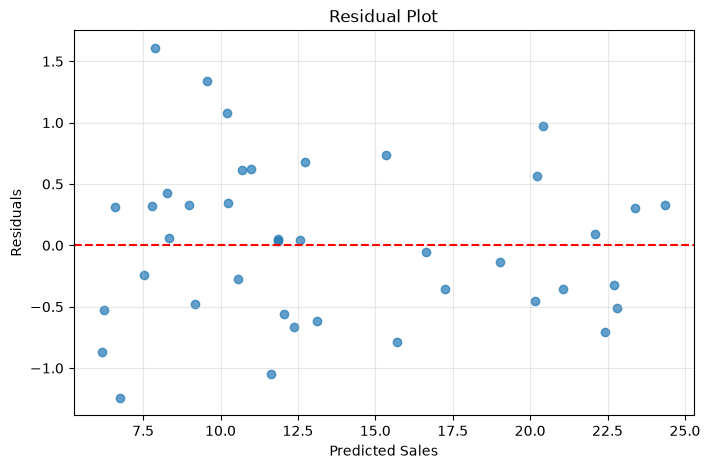

In [38]:
residuals = np.asarray(y_test) - final_predictions

plt.figure(figsize=(8, 5))

plt.scatter(final_predictions, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid(alpha=0.3)
plt.show()

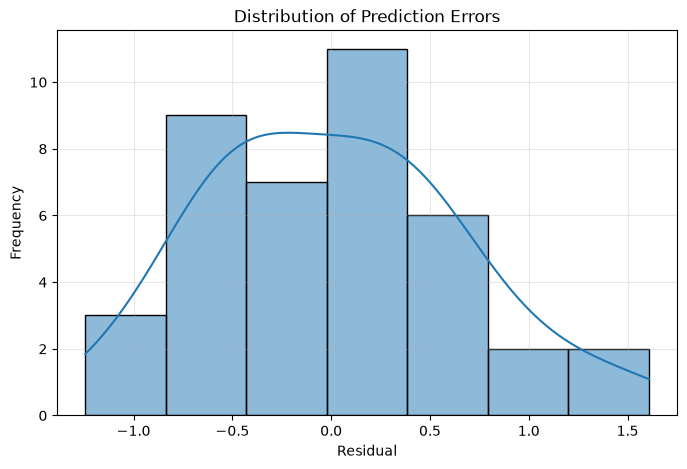

In [39]:
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.grid(alpha=0.3)
plt.show()

## 12. What-If Advertising Analysis

This section examines how predicted sales change when advertising expenditure on individual platforms increases.

The analysis uses the trained machine learning model to simulate a 10% increase in advertising expenditure for TV, Radio, and Newspaper.

These are model-based scenarios and should not be interpreted as proof of causal effects.

In [40]:
def what_if_analysis(model, input_data, feature, increase=0.10):

    original_data = input_data.copy()
    modified_data = input_data.copy()

    modified_data[feature] *= (1 + increase)

    original_prediction = model.predict(original_data)[0]
    new_prediction = model.predict(modified_data)[0]

    sales_change = new_prediction - original_prediction

    percentage_change = (
        (sales_change / original_prediction) * 100
        if original_prediction != 0
        else np.nan
    )

    return {
        "Advertising Channel": feature,
        "Original Predicted Sales": original_prediction,
        "New Predicted Sales": new_prediction,
        "Sales Change": sales_change,
        "Percentage Change": percentage_change
    }

In [41]:
reference_input = pd.DataFrame(
    [X_train.mean()],
    columns=X_train.columns
)

what_if_results = []

for channel in ["TV", "Radio", "Newspaper"]:

    result = what_if_analysis(
        best_model,
        reference_input,
        channel,
        increase=0.10
    )

    what_if_results.append(result)

what_if_df = pd.DataFrame(what_if_results)

display(what_if_df.round(3))

,Advertising Channel,Original Predicted Sales,New Predicted Sales,Sales Change,Percentage Change
0,TV,14.768,15.384,0.616,4.172
1,Radio,14.768,15.212,0.444,3.004
2,Newspaper,14.768,14.781,0.012,0.084


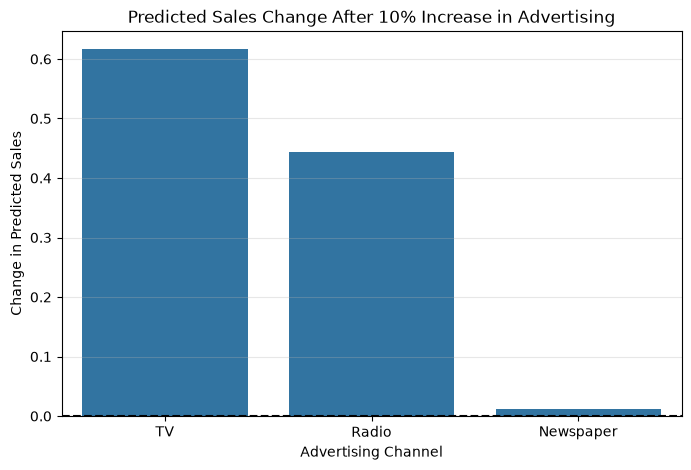

In [42]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=what_if_df,
    x="Advertising Channel",
    y="Sales Change"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Predicted Sales Change After 10% Increase in Advertising")
plt.xlabel("Advertising Channel")
plt.ylabel("Change in Predicted Sales")
plt.grid(axis="y", alpha=0.3)

plt.show()

## 13. Feature Importance and Marketing Analysis

This section identifies which advertising channels contribute most to the predictive performance of the selected model.

Permutation importance measures how much model performance decreases when a particular feature is shuffled.

A larger importance score indicates that the model relies more heavily on that feature for its predictions.

In [43]:
from sklearn.inspection import permutation_importance

importance_results = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="r2"
)

feature_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_results.importances_mean
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df)

,Feature,Importance
0,TV,1.400235
1,Radio,0.560037
2,Newspaper,0.000184


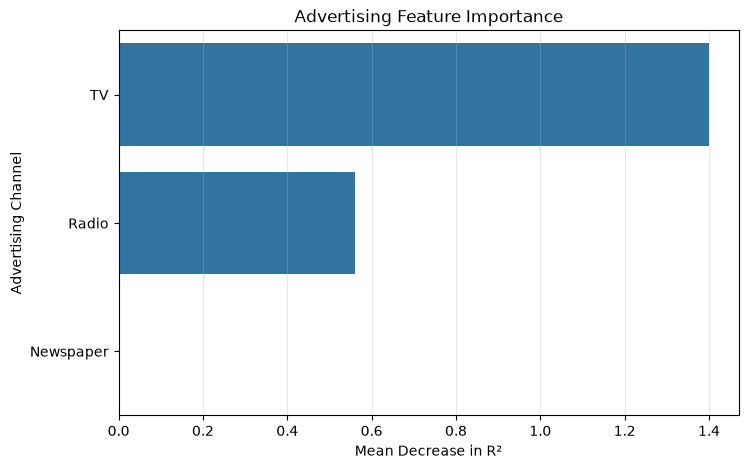

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Advertising Feature Importance")
plt.xlabel("Mean Decrease in R²")
plt.ylabel("Advertising Channel")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [45]:
advertising_spend = df[["TV", "Radio", "Newspaper"]].sum()

spend_percentage = (
    advertising_spend / advertising_spend.sum()
) * 100

spend_analysis = pd.DataFrame({
    "Advertising Channel": advertising_spend.index,
    "Total Advertising Spend": advertising_spend.values,
    "Budget Percentage": spend_percentage.values
})

display(spend_analysis.round(2))

,Advertising Channel,Total Advertising Spend,Budget Percentage
0,TV,29408.5,73.21
1,Radio,4652.8,11.58
2,Newspaper,6110.8,15.21


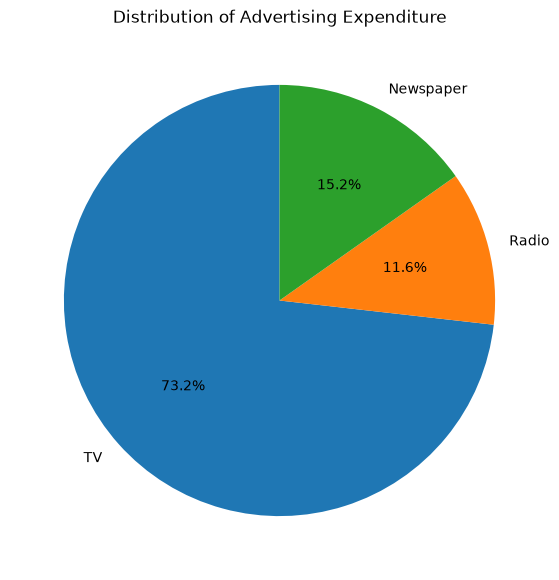

In [46]:
plt.figure(figsize=(7, 7))

plt.pie(
    spend_analysis["Total Advertising Spend"],
    labels=spend_analysis["Advertising Channel"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Advertising Expenditure")
plt.show()

## 14. Actionable Marketing Insights

The results of the exploratory analysis, regression models, feature importance analysis, and what-if simulations can help businesses make more informed advertising decisions.

The following insights are based on the observed dataset and model predictions:

1. Advertising channels with stronger relationships with sales may deserve closer attention during budget planning.
2. Feature importance helps identify which advertising variables the selected model relies on most.
3. What-if analysis provides an estimate of how predicted sales may change when advertising expenditure increases.
4. Model evaluation metrics help determine whether predictions are reliable enough to support planning.
5. Advertising expenditure should be reviewed alongside actual business outcomes before making major budget changes.

These findings represent predictive relationships in the dataset and do not establish that advertising expenditure alone causes changes in sales.

In [47]:
top_feature = feature_importance_df.iloc[0]["Feature"]
top_importance = feature_importance_df.iloc[0]["Importance"]

top_spend_channel = spend_analysis.loc[
    spend_analysis["Total Advertising Spend"].idxmax(),
    "Advertising Channel"
]

print("MARKETING INSIGHTS")
print("-" * 40)

print(
    f"The model relies most on {top_feature} "
    f"according to permutation importance."
)

print(
    f"The highest total advertising expenditure "
    f"is recorded for {top_spend_channel}."
)

print(
    f"The selected model achieved an R² score of "
    f"{final_r2:.4f}."
)

print(
    "Use the what-if analysis to compare possible "
    "advertising budget scenarios."
)

MARKETING INSIGHTS
----------------------------------------
The model relies most on TV according to permutation importance.
The highest total advertising expenditure is recorded for TV.
The selected model achieved an R² score of 0.9869.
Use the what-if analysis to compare possible advertising budget scenarios.


## 15. Saving the Trained Model

The selected machine learning model is saved so that it can be reused for future sales predictions without repeating the training process.

In [48]:
import joblib

joblib.dump(best_model, "sales_prediction_model.pkl")

print("Trained model saved successfully!")

Trained model saved successfully!


In [49]:
sample_advertising_data = pd.DataFrame(
    [[150, 25, 30]],
    columns=["TV", "Radio", "Newspaper"]
)

loaded_model = joblib.load("sales_prediction_model.pkl")

predicted_sales = loaded_model.predict(sample_advertising_data)

print("Sample Advertising Data:")
display(sample_advertising_data)

print("Predicted Sales:", round(float(predicted_sales[0]), 2))

Sample Advertising Data:


,TV,Radio,Newspaper
0,150,25,30


Predicted Sales: 15.18


## 16. Conclusion

The Sales Prediction project demonstrates how machine learning can be used to estimate product sales based on advertising expenditure across different marketing channels.

The project involved:

- Loading and understanding the advertising dataset.
- Cleaning and preprocessing the data.
- Performing exploratory data analysis.
- Studying relationships between advertising expenditure and sales.
- Selecting relevant features.
- Training and comparing multiple regression models.
- Evaluating model performance using R², MAE, RMSE, and MAPE.
- Performing what-if advertising simulations.
- Analyzing feature importance.
- Developing actionable marketing insights.

The selected model provides a data-driven approach to estimating sales and examining potential advertising scenarios.

This project demonstrates the practical application of Python, data analysis, visualization, and machine learning in marketing analytics.